# 06 · End-to-End System Demo

**Use Case 3: Research Paper Analysis and Recommendation System**  
**Owner:** Member D (integration), with input from all members

**Goal:** Run the full pipeline on a few live queries: query → preprocess → classify → retrieve → LLM summary, gaps and recommendations.

**Basic techniques (Weeks 1–6)**
- Reuses the preprocessing (02), classifier (03) and similarity (04) components

**Advanced techniques (Weeks 7–12)**
- Reuses the RAG synthesis prompt, the safety system prompt and the groundedness judge from 05 (shared in `rag.py`) in one `analyse(query)` function. Chain-of-thought gap analysis is evaluated in 05 but not called here. The few-shot single-paper summariser is called for abstract inputs.

**Evaluation:** 3–5 worked demo queries with outputs shown, plus a short quality table (latency is reported separately because cached LLM calls take 0 s). This notebook is the one shown in the presentation.

**Report section:** Feeds the system-architecture and results sections.

## Setup

Run `01_data_loading_and_sampling.ipynb` first. Always evaluate on `test_df`.

In [1]:
from utils import load_sample, load_split

df = load_sample()
train_df, test_df = load_split(df)
print(f"all={len(df):,}  train={len(train_df):,}  test={len(test_df):,}")
train_df[["id", "primary_category", "title"]].head()

all=12,000  train=9,600  test=2,400


,id,primary_category,title
0,2404.00934,cs.CL,ChatGLM-RLHF: Practices of Aligning Large Lang...
1,2304.01712,cs.CL,Rumour Detection and Analysis on Twitter
2,2509.24120,cs.CL,EduVidQA: Generating and Evaluating Long-form ...
3,1706.03747,cs.CL,Acoustic data-driven lexicon learning based on...
4,1805.04793,cs.CL,Coarse-to-Fine Decoding for Neural Semantic Pa...


## Load components

Every stage reuses a module or artifact from notebooks 02–05; no model is trained here.

| Stage | Component | Built in |
|---|---|---|
| key phrases and named methods/datasets | `extraction.extract`; the evaluated few-shot LLM + regex hybrid is used for abstracts | 02 |
| domain classification | `classify.predict` (TF-IDF + LogReg, `artifacts/classifier.pkl`) | 03 |
| retrieval | `retrieval.retrieve` / `retrieval.recommend` (MiniLM) | 04 |
| single-paper summary (pasted abstract) | `rag.summarise_abstract`, the few-shot prompt evaluated in 05 | 05 |
| synthesis, gap, recommendations, checks | `rag.build_rag_prompt`, citation coverage, exact cited-source matching and groundedness | 05 |

If the classifier pickle is unavailable, the domain is marked `n/a`. Retrieval and the LLM are required for this demonstration.


In [2]:
import json
import re
import time
import os

import pandas as pd
import transformers

import llm
import rag
import extraction as ex
from utils import retrieve, load_results, save_results, ARTIFACTS_DIR

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
transformers.logging.set_verbosity_error()

try:
    import classify as clf
    clf.load_classifier()
    HAVE_CLASSIFIER = True
except Exception as e:                       # pickle not built on this machine
    HAVE_CLASSIFIER = False
    print("classifier unavailable:", e)

import retrieval
HAVE_MINILM = retrieval.EMB_PATH.exists()
print("LLM:", llm.describe(), "| classifier:", HAVE_CLASSIFIER, "| MiniLM index cached:", HAVE_MINILM)

LLM: {'backend': 'hf', 'model': 'Qwen/Qwen2.5-1.5B-Instruct'} | classifier: True | MiniLM index cached: True


## `analyse(query)` pipeline

A short topic query uses key phrases and regex; a pasted abstract uses the evaluated few-shot LLM + regex hybrid. Both are classified and matched to five papers. An abstract also receives the few-shot single-paper summary from notebook 05. Retrieved abstracts pass through `rag.sanitize`, which removes instruction-like sentences (prompt injection) before they enter the prompt. The RAG synthesis is then filtered sentence by sentence (`rag.filter_cited_claims`): a sentence is kept only if it cites a retrieved paper as [n], does not misstate the number of papers, and the judge finds it supported by the excerpt of the paper it cites. Dropped sentences are listed with their reason. Only if no sentence survives do cited source sentences replace the synthesis as an explicit fallback. Exact-copy matching is still reported, but no longer used as a gate, because it rejects every faithful paraphrase. The generated gap and recommendation reasons are not covered by that fallback check. For a paper already in the sample, `recommend(paper_id)` excludes that paper itself; an exact pasted abstract is also filtered from free-text retrieval.


In [3]:
def analyse(query, k=5, paper_id=None):
    """Analyse a topic query or a paper already in the sample (pass its id)."""
    t0 = time.time()
    result = {"query": query}
    is_paper_text = paper_id is not None or len(query.split()) >= 40
    info = ex.extract(query)
    result["key_phrases"] = info["key_phrases"][:6]
    result["domain"] = clf.predict([query])[0] if HAVE_CLASSIFIER else "n/a (classifier not built)"
    if paper_id:
        hits = retrieval.recommend(paper_id, k=k)
        result["self_match_excluded"] = True
    elif is_paper_text:
        candidates = retrieve(query, k=k + 5)
        query_text = ex.clean_text(query).casefold()
        is_self = candidates["abstract"].map(lambda a: ex.clean_text(a).casefold() in query_text)
        hits = candidates.loc[~is_self].head(k).reset_index(drop=True)
        result["self_match_excluded"] = bool(is_self.any())
    else:
        hits = retrieve(query, k=k)
        result["self_match_excluded"] = False
    result["papers"] = hits[["id", "primary_category", "title", "score"]].to_dict(orient="records")
    result["retrieved_domains"] = hits["primary_category"].value_counts().to_dict()
    result["seconds_before_llm"] = round(time.time() - t0, 2)

    llm_start = time.time()
    if is_paper_text:
        extracted = ex.llm_extract(query, shots=3)
        hybrid = ex.hybrid_artefacts(extracted["methods"] + extracted["datasets"], query)
        result["entities"] = hybrid[:6]
        result["extraction_method"] = "few-shot LLM + regex"
        result["summary"] = rag.summarise_abstract(query)
    else:
        result["entities"] = (info["acronyms"] + info["datasets"])[:6]
        result["extraction_method"] = "regex for short topic query"
        result["summary"] = None

    prompt = rag.build_rag_prompt(query, hits, cite_every_sentence=True)     # v2 prompt from notebook 05.1
    result["llm_cached"] = llm.is_cached(prompt, system=rag.SYSTEM + rag.GUARD, max_new_tokens=450)
    reply = llm.generate(prompt, system=rag.SYSTEM + rag.GUARD, max_new_tokens=450)
    result["reply"] = reply
    result.update(rag.parse_sections(reply))
    result["gap_verified"] = False
    result["recommendations_verified"] = False

    # Metrics for the whole generated synthesis, reported but not used as the gate
    source = rag.hits_source(hits)
    supported, n = rag.groundedness(result["synthesis"], source, expected_papers=len(hits))
    citations = rag.validate_citations(result["synthesis"], len(hits))
    exact_cited, _ = rag.exact_citation_support(result["synthesis"], hits, prompt_only=True)
    result["generated_synthesis"] = result["synthesis"]
    result["generated_synthesis_grounded_share"] = round(supported / n, 2) if n else None
    result["generated_synthesis_claims"] = n
    result["generated_synthesis_citation_coverage"] = citations["coverage"]
    result["generated_synthesis_exact_cited_claims"] = exact_cited

    # Gate: keep each sentence that cites a paper and is supported by the paper it cites
    check = rag.filter_cited_claims(result["synthesis"], hits)
    result["kept_claims"] = len(check["kept"])
    result["dropped_claims"] = check["dropped"]
    result["synthesis_fallback"] = not check["kept"]
    if check["kept"]:
        result["synthesis"] = " ".join(check["kept"])
        result["synthesis_verification"] = "per-claim LLM judge against the cited paper"
        supported = n = len(check["kept"])
    else:
        result["synthesis"] = rag.evidence_synthesis(hits)
        result["synthesis_verification"] = "exact source match"
        supported, n = rag.verify_evidence_synthesis(result["synthesis"], hits)
    citations = rag.validate_citations(result["synthesis"], len(hits))

    result["grounded_share"] = round(supported / n, 2) if n else None
    result["n_claims"] = n
    result["citation_coverage"] = citations["coverage"]
    result["invalid_citations"] = citations["invalid_references"]
    result["exact_citation_supported_claims"], _ = rag.exact_citation_support(result["synthesis"], hits)
    result["synthesis_verified"] = bool(n and supported == n and citations["coverage"] == 1
                                         and not citations["invalid_references"])
    result["seconds_llm"] = round(time.time() - llm_start, 1)
    return result


def show(r):
    print("=" * 100)
    print("QUERY:", r["query"][:160] + ("..." if len(r["query"]) > 160 else ""))
    print(f"domain: {r['domain']}   key phrases: {r['key_phrases']}   methods/datasets: {r['entities']}")
    print("\nRETRIEVED:")
    for i, p in enumerate(r["papers"]):
        print(f"  [{i + 1}] {p['score']:.2f} [{p['primary_category']}] {p['id']} {p['title'][:80]}")
    if r["summary"]:
        print("\nSINGLE-PAPER SUMMARY:", r["summary"])
    label = ("EXTRACTIVE EVIDENCE FALLBACK" if r["synthesis_fallback"] else
             f"RAG SYNTHESIS ({r['kept_claims']} of {r['generated_synthesis_claims']} generated claims kept)")
    print(f"\n{label}:", r["synthesis"])
    for sentence, reason in r["dropped_claims"]:
        print(f"  dropped ({reason}): {sentence[:110]}")
    print("\nGAP (not independently checked):", r["gap"] or "(none found)",
          "(taken from the synthesis text)" if r["gap_from_fallback"] else "")
    print("\nRECOMMENDATIONS (reasons not independently checked):\n" +
          (r["recommendations"] or "(none found)"))
    print(f"\nsynthesis grounded {r['grounded_share']:.0%} of {r['n_claims']} claims; "
          f"citation coverage {r['citation_coverage']:.0%}; exact-source citations "
          f"{r['exact_citation_supported_claims']}/{r['n_claims']}; verified={r['synthesis_verified']} "
          f"({r['synthesis_verification']}); format_ok={r['format_ok']}")
    print(f"pipeline before LLM {r['seconds_before_llm']} s; all LLM work {r['seconds_llm']} s "
          f"(RAG response cached: {r['llm_cached']})")
    if r["synthesis_fallback"]:
        print("No generated synthesis sentence passed the per-claim check; gap and recommendation reasons remain unverified.")


## Demo queries

Three queries of different kinds: a method question, an application question, and a full abstract pasted in as the query (the "analyse this paper" use).

In [4]:
demo_paper = test_df.sample(n=1, random_state=7).iloc[0]                  # a whole abstract as the query
DEMO_QUERIES = [
    ("defending large language models against prompt injection and jailbreak attacks", None),
    ("using graph neural networks to recommend items to users", None),
    (demo_paper["abstract"], demo_paper["id"]),
]
demo_results = []
for q, pid in DEMO_QUERIES:
    r = analyse(q, paper_id=pid)
    demo_results.append(r)
    show(r)
assert all(r["synthesis"] and r["gap"] and r["recommendations"] for r in demo_results), "a section is empty"
assert demo_paper["id"] not in [p["id"] for p in demo_results[2]["papers"]], "query paper retrieved itself"

QUERY: defending large language models against prompt injection and jailbreak attacks
domain: cs.CR   key phrases: ['large language models', 'prompt injection', 'jailbreak attacks']   methods/datasets: []

RETRIEVED:
  [1] 0.78 [cs.CR] 2409.00137 Emerging Vulnerabilities in Frontier Models: Multi-Turn Jailbreak Attacks
  [2] 0.77 [cs.CR] 2408.04811 h4rm3l: A language for Composable Jailbreak Attack Synthesis
  [3] 0.74 [cs.LG] 2505.11790 JULI: Jailbreak Large Language Models by Self-Introspection
  [4] 0.74 [cs.CR] 2407.01902 SeqAR: Jailbreak LLMs with Sequential Auto-Generated Characters
  [5] 0.73 [cs.CR] 2506.10597 SoK: Evaluating Jailbreak Guardrails for Large Language Models

EXTRACTIVE EVIDENCE FALLBACK: [1] Large language models (LLMs) are improving at an exceptional rate. [2] Despite their demonstrated valuable capabilities, state-of-the-art (SOTA) widely deployed large language models (LLMs) still have the potential to cause harm to society due to the ineffectiveness of their 

In [5]:
pd.DataFrame([{"query": r["query"][:70] + ("..." if len(r["query"]) > 70 else ""),
               "domain": r["domain"], "retrieved domains": r["retrieved_domains"],
               "generated grounded": r["generated_synthesis_grounded_share"],
               "kept claims": f"{r['kept_claims']}/{r['generated_synthesis_claims']}",
               "final grounded": r["grounded_share"], "citation coverage": r["citation_coverage"],
               "fallback": r["synthesis_fallback"], "verified": r["synthesis_verified"],
               "s before LLM": r["seconds_before_llm"], "all LLM s": r["seconds_llm"]}
              for r in demo_results])


,query,domain,retrieved domains,generated grounded,kept claims,final grounded,citation coverage,fallback,verified,s before LLM,all LLM s
0,defending large language models against prompt...,cs.CR,"{'cs.CR': 4, 'cs.LG': 1}",0.33,0/3,1.0,1.0,True,True,2.47,0.0
1,using graph neural networks to recommend items...,cs.LG,{'cs.IR': 5},1.00,0/3,1.0,1.0,True,True,0.02,0.0
2,We present an introduction and a review of the...,cs.AI,"{'cs.AI': 3, 'cs.IR': 1, 'cs.CL': 1}",0.50,0/2,1.0,1.0,True,True,0.02,0.0


**Latency.** `seconds_before_llm` covers basic extraction, classification and retrieval. `seconds_llm` covers few-shot extraction, the optional single-paper summary, RAG generation and groundedness checks. `llm_cached` describes only the RAG generation call, so it is not a claim that the entire LLM stage was cached. The first query also pays model-loading time.


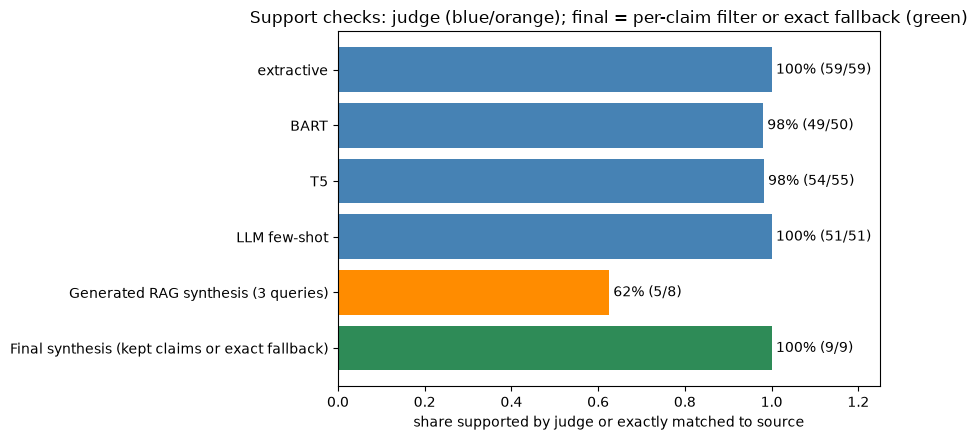

In [6]:
# Groundedness chart (Week 10): generated RAG output and final output are kept separate.
import matplotlib.pyplot as plt
from utils import load_results, ARTIFACTS_DIR

r05 = load_results("05")
names = [row["summariser"] for row in r05["groundedness"]]
supported = [row["supported"] for row in r05["groundedness"]]
total = [row["claims"] for row in r05["groundedness"]]

original_supported = sum(round(r["generated_synthesis_grounded_share"] * r["generated_synthesis_claims"])
                         for r in demo_results if r["generated_synthesis_claims"])
original_total = sum(r["generated_synthesis_claims"] for r in demo_results)
final_supported = sum(round(r["grounded_share"] * r["n_claims"]) for r in demo_results if r["n_claims"])
final_total = sum(r["n_claims"] for r in demo_results)
names += [f"Generated RAG synthesis ({len(demo_results)} queries)", "Final synthesis (kept claims or exact fallback)"]
supported += [original_supported, final_supported]
total += [original_total, final_total]
rates = [s / t if t else 0 for s, t in zip(supported, total)]

colours = ["steelblue"] * (len(names) - 2) + ["darkorange", "seagreen"]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(names, rates, color=colours)
ax.invert_yaxis()
ax.set_xlim(0, 1.25)
ax.set_xlabel("share supported by judge or exactly matched to source")
ax.set_title("Support checks: judge (blue/orange); final = per-claim filter or exact fallback (green)")
for i, (rate, s, t) in enumerate(zip(rates, supported, total)):
    ax.text(rate + 0.01, i, f"{rate:.0%} ({s}/{t})", va="center")
plt.tight_layout()
plt.savefig(ARTIFACTS_DIR / "06_groundedness.png", dpi=200, bbox_inches="tight")
plt.show()


## Summary table

Headline numbers from every notebook, read from `artifacts/*_results.json` (no notebook is re-run here). This is the results slide.

In [7]:
r02, r03, r04, r05 = (load_results(n) for n in ["02", "03", "04", "05"])
rows = []


def add(nb, technique, week, metric, value, note=""):
    rows.append({"notebook": nb, "technique": technique, "week": week, "metric": metric, "value": value, "note": note})


# 02
if isinstance(r02.get("extraction_scores"), list):
    for s in r02["extraction_scores"]:
        add("02", f"extraction: {s['extractor']}", "W3 / W9", "F1 (20 provisional abstracts)", s["f1"])
else:
    add("02", "extraction P/R/F1", "W3 / W9", "F1", "not run", "gold labels not filled in")
add("02", "preprocessing: vocab after lemmatisation", "W2", "vocab size (1k abstracts)", r02.get("vocab_reduction_1000_abstracts", {}).get("+ spaCy lemmatisation"))
# 03
for m in r03.get("models", []):
    add("03", f"classifier: {m['model']}", "W5-W9", "macro-F1", m["macro_f1"], m.get("note", ""))
for m in r03.get("short_input_check", {}).get("rows", []):
    if m["model"] == "LogReg, title only":
        add("03", "classifier: LogReg, title only", "W5", "macro-F1", m["macro_f1"], "title-only proxy for short queries")
# 04
for m in r04.get("retrieval_eval", []):
    add("04", f"retrieval: {m['retriever']}", "W4 / W8 / W12", "nDCG@5", m["nDCG@5"])
deployed = r04.get("deployed_retrieval_eval")
if deployed:
    add("04", "retrieval: MiniLM deployed 12k (self excluded)", "W12", "nDCG@5", deployed["nDCG@5"])
for m in r04.get("clustering", []):
    add("04", f"clustering: {m['space']}", "W4", "purity", m["purity"])
# 05
for m in r05.get("rouge", []):
    add("05", f"summary: {m['system']}", "W9", "ROUGE-L", m["rougeL"])
for m in r05.get("rubric_1_to_5", []):
    add("05", f"summary: {m['system']}", "W9", "rubric 1-5", m["mean"])
for m in r05.get("groundedness", []):
    add("05", f"groundedness: {m['summariser']}", "W10", "supported claims", m["grounded_rate"])
for m in r05.get("rag_ablation", []):
    add("05", f"RAG synthesis: {m['mode']}", "W11-12", "claims supported by retrieved papers", m["grounded rate"])
    if "cited synthesis claims" in m:
        add("05", f"RAG synthesis: {m['mode']}", "W11-12", "claims with an in-range [n] marker",
            m["cited synthesis claims"])
    if "exact-source cited claims" in m:
        add("05", f"RAG synthesis: {m['mode']}", "W11-12", "exact-source cited claims", m["exact-source cited claims"])
for m in r05.get("cot_ablation", []):
    add("05", f"research gap: {m['prompt']}", "W8-9", "specificity (gap words in abstract)", m["specificity"])
if "judge_validation" in r05:
    for k, v in r05["judge_validation"].items():
        add("05", f"judge validation: {k}", "W10", "count", v)
if "prompt_injection" in r05:
    pi = r05["prompt_injection"]
    add("05", "prompt injection, no guard sentence", "W10", "attacks succeeded", f"{pi['succeeded_unguarded']}/{pi['attempts_per_setting']}")
    add("05", "prompt injection, guard sentence", "W10", "attacks succeeded", f"{pi['succeeded_guarded']}/{pi['attempts_per_setting']}")
# 05.1 (revision of 05: v2 RAG prompt, per-claim filter, sanitizer)
r051 = load_results("05_1")
for m in r051.get("rag_v1_vs_v2", []):
    add("05.1", f"RAG synthesis: {m['version']}", "W11-12", "kept by per-claim filter", m["kept by per-claim filter"])
for m in r051.get("prompt_injection", []):
    add("05.1", f"prompt injection, {m['attacks']} attacks, {m['setting']}", "W10", "attacks succeeded",
        m["succeeded (incl. partial hijack)"], "counts partial hijacks")

summary = pd.DataFrame(rows)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 60)
summary

,notebook,technique,week,metric,value,note
0,02,extraction: Regex rules (W3),W3 / W9,F1 (20 provisional abstracts),0.466,
1,02,extraction: spaCy NER ORG/PRODUCT (W3),W3 / W9,F1 (20 provisional abstracts),0.376,
2,02,extraction: Zero-shot LLM (W9),W3 / W9,F1 (20 provisional abstracts),0.44,
3,02,extraction: Few-shot LLM (W9),W3 / W9,F1 (20 provisional abstracts),0.599,
4,02,extraction: Hybrid: few-shot LLM + regex,W3 / W9,F1 (20 provisional abstracts),0.634,
...,...,...,...,...,...,...
64,05.1,"prompt injection, original attacks, guard",W10,attacks succeeded,3/9,counts partial hijacks
65,05.1,"prompt injection, original attacks, sanitize + guard",W10,attacks succeeded,0/9,counts partial hijacks
66,05.1,"prompt injection, held-out attacks, none",W10,attacks succeeded,4/9,counts partial hijacks
67,05.1,"prompt injection, held-out attacks, guard",W10,attacks succeeded,4/9,counts partial hijacks


In [8]:
save_results("06", {"demo": [{k: v for k, v in r.items() if k not in ("papers", "reply")} | {"paper_ids": [p["id"] for p in r["papers"]]}
                             for r in demo_results],
                    "components": {"classifier": HAVE_CLASSIFIER, "minilm_index": HAVE_MINILM, "llm": llm.describe()}})
summary.to_csv(ARTIFACTS_DIR / "06_summary_table.csv", index=False)
print("Saved artifacts/06_results.json and artifacts/06_summary_table.csv")

Saved artifacts/06_results.json and artifacts/06_summary_table.csv


## Future extensions

A voice interface could transcribe a spoken question before calling `analyse()`. An agent wrapper could choose when to retrieve or summarise. Neither extension is implemented or included in the results; the current arXiv metadata also has no images for VQA.
